In [25]:
#Unpickling the data
import pickle

# to load the data using pickle we will 
with open(r"C:\Users\subha\OneDrive\Desktop\FacedetectionANDattendanceSystem\data\images.p","rb") as f:
  images = pickle.load(f) 
with open(r"C:\Users\subha\OneDrive\Desktop\FacedetectionANDattendanceSystem\data\labels.p","rb") as f:
  labels = pickle.load(f)

In [26]:
print(images.shape)
print(labels.shape)

(200, 100, 100)
(200,)


In [27]:
set(labels)

{'linty', 'subham'}

In [28]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

labels = le.fit_transform(labels)

In [29]:
set(labels)

{0, 1}

In [30]:
le.inverse_transform([0,1])

array(['linty', 'subham'], dtype='<U6')

In [31]:
p = len(set(labels))
print("Total number of Persons : ",p)

Total number of Persons :  2


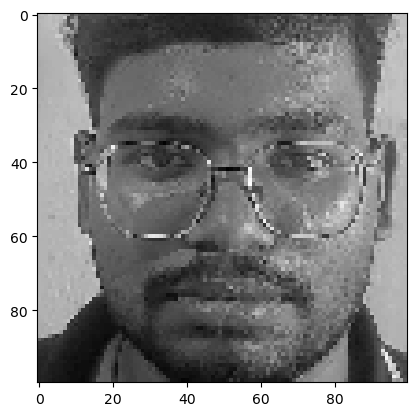

In [32]:
import matplotlib.pyplot as plt
plt.imshow(images[90],cmap='gray')
plt.show()

In [33]:
import cv2

In [34]:
def preprocessing(img):
  img = cv2.equalizeHist(img)
  img = img.reshape(100,100,1)
  img = img/255
  return img

In [35]:
import numpy as np

In [36]:
images = np.array(list(map(preprocessing,images)))
print("Shape of Input : ",images.shape)

Shape of Input :  (200, 100, 100, 1)


In [37]:
from keras.utils import to_categorical
labels = to_categorical(labels)

In [38]:
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import Adam

from keras.layers import Conv2D, MaxPooling2D, Flatten

In [39]:
#Model Training
def Lenet_Model():
  model = Sequential()
  #Convolutional and ReLU Layer
  model.add(Conv2D(30,(5,5),input_shape=(100,100,1),
                   activation='relu'))
  #MaxPooling Layer
  model.add(MaxPooling2D(pool_size=(2,2)))

  #Convolutional and ReLU Layer
  model.add(Conv2D(15,(3,3),activation='relu'))
  #MaxPooling Layer
  model.add(MaxPooling2D(pool_size=(2,2)))

  #Flatten Layer/Input Layer
  model.add(Flatten())

  #Hidden Layers
  model.add(Dense(50,activation='relu'))

  #Output Layer
  model.add(Dense(p,activation='softmax'))
  model.compile(Adam(learning_rate=0.01),
                loss='categorical_crossentropy',
                metrics=['accuracy'])
  return model

In [40]:
model = Lenet_Model()
model.summary()

C:\Users\subha\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 96, 96, 30)     │           780 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 48, 48, 30)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 46, 46, 15)     │         4,065 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 23, 23, 15)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 7935)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 50)             │       396,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 401,747 (1.53 MB)

 Trainable params: 401,747 (1.53 MB)

 Non-trainable params: 0 (0.00 B)

In [41]:
h = model.fit(images,labels,
              validation_split=0.1,epochs=10)

Epoch 1/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 143ms/step - accuracy: 0.5556 - loss: 4.7231 - val_accuracy: 0.0000e+00 - val_loss: 0.6995
Epoch 2/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.5556 - loss: 0.6615 - val_accuracy: 0.0000e+00 - val_loss: 0.7361
Epoch 3/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.5556 - loss: 0.6861 - val_accuracy: 0.7000 - val_loss: 0.6809
Epoch 4/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.9389 - loss: 0.3369 - val_accuracy: 1.0000 - val_loss: 6.4716e-04
Epoch 5/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 1.0000 - loss: 0.0026 - val_accuracy: 0.9500 - val_loss: 0.0741
Epoch 6/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - accuracy: 1.0000 - loss: 8.7788e-04 - val_accuracy: 0.9500 - val_loss: 0.2364
Epoch 7/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 84ms/step - accuracy: 1.0000 - loss: 7.6457e-04 - val_accuracy: 0.9500 - val_loss: 0.1782
Epoch 8/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 1.0000 - loss: 2.5473e-05 - val_accuracy: 0

In [42]:
model.save('final_model.h5')

In [43]:
# def fun(n):
#     return n**2

In [44]:
# fun(5)

In [45]:
# li = [2,3,4,5]

# fun(li)

In [46]:
# #map
# #map(function,seq)
# map(fun,li)

In [47]:
# list(map(fun,li))

In [48]:
# def fun(n):
#     return n**2

In [49]:
# fun(5)

In [50]:
# li = [2,3,4,5]
# fun(li)

In [51]:
# map(fun,li)

In [52]:
# list(map(fun,li))

In [53]:
# def fun(n):
#     return n**2

In [54]:
# fun(5)

In [55]:
# li = [2,3,4]
# fun(li)

In [56]:
# list(map(fun,li))